## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Lani Le

**Date:** 10/12/26

In [390]:
# Your Phase 1 solution to the problem goes here.

print('---------------Question 1.1---------------')
# running given code

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

---------------Question 1.1---------------


---------------Question 1.2---------------
As the noise goes up from 0.125 to 2.0, the points get progressively more dispered from their concentraated clusters. From low noise levels, like 0.125 to 0.25, there are 3 clearly seperated groups, but as the noise increases higher, the distinction between the groups disappear, as the clusters are expanding.


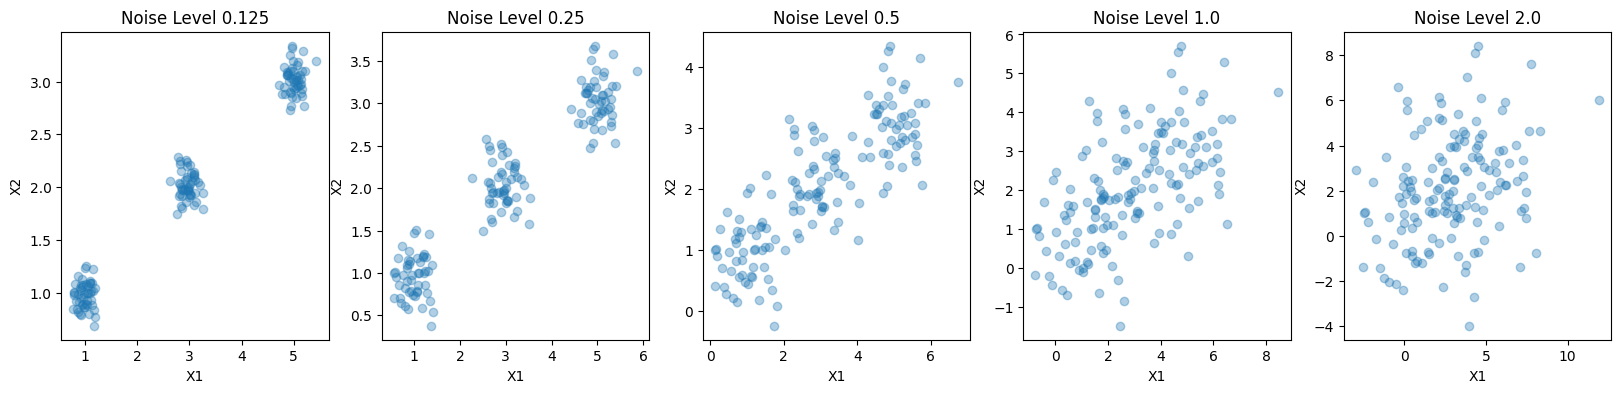

In [391]:
print('---------------Question 1.2---------------')

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# making scatterplots
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# scatterplot for noise level 0.125
axes[0].scatter(data=df0_125, x='x1', y='x2', alpha=0.35)
axes[0].set(title='Noise Level 0.125', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 0.25
axes[1].scatter(data=df0_25, x='x1', y='x2', alpha=0.35)
axes[1].set(title='Noise Level 0.25', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 0.5
axes[2].scatter(data=df0_5, x='x1', y='x2', alpha=0.35)
axes[2].set(title='Noise Level 0.5', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 1.0
axes[3].scatter(data=df1_0, x='x1', y='x2', alpha=0.35)
axes[3].set(title='Noise Level 1.0', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 2.0
axes[4].scatter(data=df2_0, x='x1', y='x2', alpha=0.35)
axes[4].set(title='Noise Level 2.0', xlabel = 'X1', ylabel='X2')

print('As the noise goes up from 0.125 to 2.0, the points get progressively more dispered from their concentraated clusters. From low noise levels, like 0.125 to 0.25, there are 3 clearly seperated groups, but as the noise increases higher, the distinction between the groups disappear, as the clusters are expanding.')

---------------Question 1.3---------------


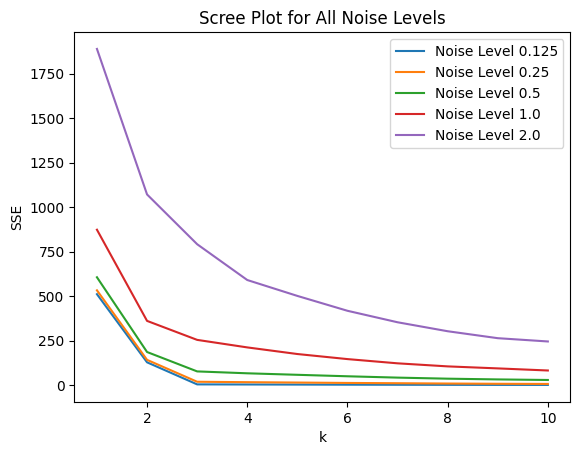

In [392]:
print('---------------Question 1.3---------------')
# making scree plots

ks = np.arange(1, 11)

# scree plot for noise level 0.125
SSE_0_125 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_125, label='Noise Level 0.125')

# scree plot for noise level 0.25
SSE_0_25 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_25, label='Noise Level 0.25')

# scree plot for noise level 0.5
SSE_0_5 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_5, label='Noise Level 0.5')

# scree plot for noise level 1.0
SSE_1_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_1_0, label='Noise Level 1.0')

# scree plot for noise level 2.0
SSE_2_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_2_0, label='Noise Level 2.0')

axes.set_title('Scree Plot for All Noise Levels')
axes.set_xlabel('k')
axes.set_ylabel('SSE')
axes.legend()

In [393]:
print('The greater noise level, the more smoothened out the sharp elbow bend at k=3 is. This is seen as the curve for Noise Level 2.0 is almost completely flattened out at k=3.')

The greater noise level, the more smoothened out the sharp elbow bend at k=3 is. This is seen as the curve for Noise Level 2.0 is almost completely flattened out at k=3.


In [394]:
print('---------------Question 1.4---------------')
print('When there is a lot of noise, the cluster groups come together so it is like a giant dispersed group, so then changing the k would not really make as big of a change, which is why the sharp elbow bend smoothens out.')


---------------Question 1.4---------------
When there is a lot of noise, the cluster groups come together so it is like a giant dispersed group, so then changing the k would not really make as big of a change, which is why the sharp elbow bend smoothens out.


In [395]:
print('---------------Question 2.1---------------')
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# loading in file
df = pd.read_csv('SIPRI Military Expenditure Database.csv')

# filtering and cleaning dataset
df_2020 = df[df['Year'] == 2020].copy()
df_2020 = df_2020.dropna() # drop missing values
print(df_2020.isnull().sum()) # check if there is still any missing values
df_2020.count() # check that there is 148 countries
print()
print(df_2020.dtypes, '\n') # gives each columns type

---------------Question 2.1---------------
index                             0
Year                              0
Country                           0
Spending (2020 USD)               0
Percent of GDP                    0
Percent of Government Spending    0
Spending per Capita               0
dtype: int64

index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 



In [396]:
df_2020.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [397]:
df_2020['Country'].unique()

array(['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina',
       'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain',
       'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia',
       'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei',
       'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon',
       'Canada', 'Cape Verde', 'Central African Republic', 'Chad',
       'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic',
       'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic',
       'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia',
       'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The',
       'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea',
       'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'India',
       'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy',
       'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya',
       'Korea, South', 'Kosovo',

In [398]:
print('Given that I was able to drop the missing values and result with 148 countries left with no duplicates, and the variables being of the correct data type, I do not think there is any further cleaning of the variables required.')

Given that I was able to drop the missing values and result with 148 countries left with no duplicates, and the variables being of the correct data type, I do not think there is any further cleaning of the variables required.


---------------Question 2.2---------------


[Text(0.5, 1.0, 'Scree Plot: Spending and Spending per Capita'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

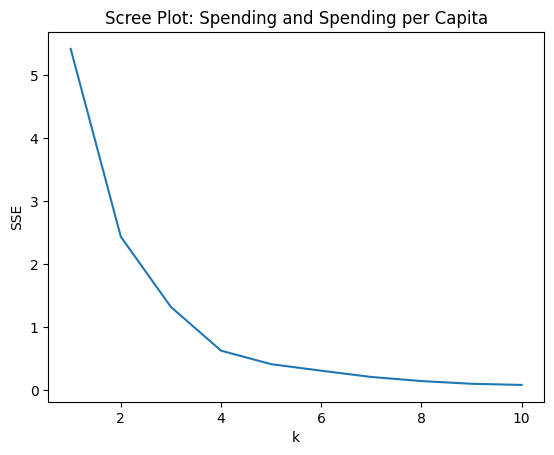

In [399]:
print('---------------Question 2.2---------------')
df_2020_scaled = MinMaxScaler().fit_transform(df_2020[['Spending (2020 USD)', 'Spending per Capita']])

ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df_2020_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot: Spending and Spending per Capita', xlabel='k', ylabel='SSE')

The optimal k is k=3, as that is where the elbow bend is located.


Text(0, 0.5, 'Spending per Capita')

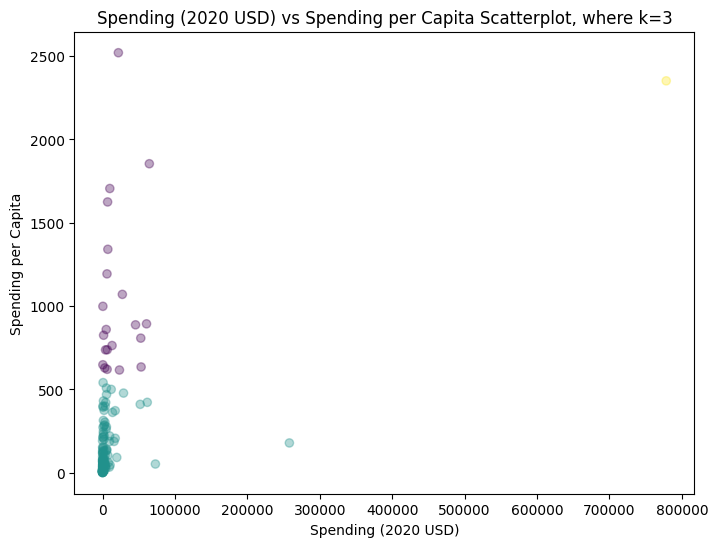

In [400]:
print('The optimal k is k=3, as that is where the elbow bend is located.')

optimal_k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
df_2020['cluster'] = kmeans.fit_predict(df_2020_scaled)

fig, axes = plt.subplots(figsize=(8, 6))
axes.scatter(df_2020['Spending (2020 USD)'], df_2020['Spending per Capita'], alpha=0.35, c=df_2020['cluster'])
axes.set_title('Spending (2020 USD) vs Spending per Capita Scatterplot, where k=3')
axes.set_xlabel('Spending (2020 USD)')
axes.set_ylabel('Spending per Capita')

In [401]:
print(df_2020.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita']].describe())
print()
print(df_2020[['Country', 'cluster']].sort_values('cluster'))
print('The United States is cluster 2, which had both an extremely high total spending of about 147964 and an extremely high spending per capita of about 1875. I noticed that most countries clustered together on the lower end, but large, more powerful/influential countries, such as the US, were in their own seperate cluster.')

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

---------------Question 2.3---------------


[Text(0.5, 1.0, 'Scree Plot: Percent of Government Spending and Percent of GDP')]

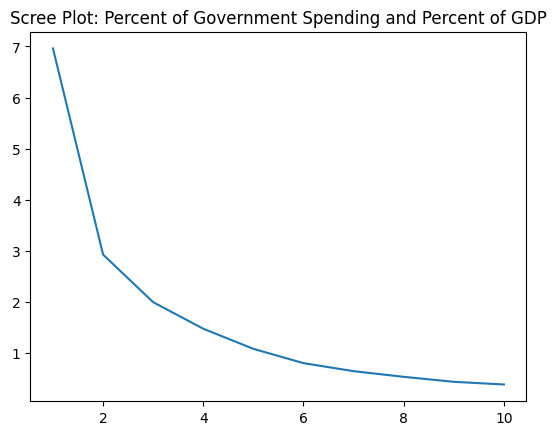

In [402]:
print('---------------Question 2.3---------------')
df_2020_scaled = MinMaxScaler().fit_transform(df_2020[['Percent of Government Spending', 'Percent of GDP']])

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df_2020_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot: Percent of Government Spending and Percent of GDP')

The optimal k is k=3, as that is where the elbow bend is located.


Text(0, 0.5, 'Percent of GDP')

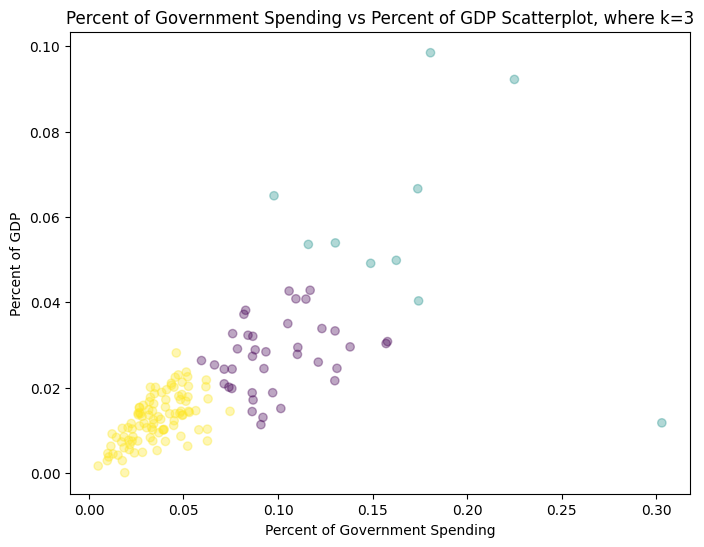

In [403]:
print('The optimal k is k=3, as that is where the elbow bend is located.')

optimal_k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
df_2020['cluster'] = kmeans.fit_predict(df_2020_scaled)

fig, axes = plt.subplots(figsize=(8, 6))
axes.scatter(df_2020['Percent of Government Spending'], df_2020['Percent of GDP'], alpha=0.35, c=df_2020['cluster'])
axes.set_title('Percent of Government Spending vs Percent of GDP Scatterplot, where k=3')
axes.set_xlabel('Percent of Government Spending')
axes.set_ylabel('Percent of GDP')

In [404]:
print(df_2020.groupby('cluster')[['Percent of Government Spending', 'Percent of GDP']].describe())
print()
print(df_2020[['Country', 'cluster']].sort_values('cluster'))
print('There are still 3 clusters, but the data points in each cluster were more closely together. Most of the countries were clustering together on the lower end. Countries on the higher end were ones that had high percentages of government spending and high percentages of GDP.')

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%   

---------------Question 2.4---------------


[Text(0.5, 1.0, 'Scree Plot: All 4 Variables')]

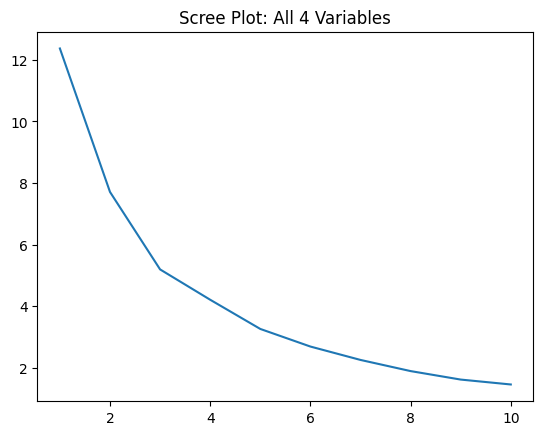

In [405]:
print('---------------Question 2.4---------------')

df_2020_scaled = MinMaxScaler().fit_transform(df_2020[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']])

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df_2020_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot: All 4 Variables')

The optimal k is k=3, as that is where the elbow bend is located.


Text(0, 0.5, 'Spending per Capita')

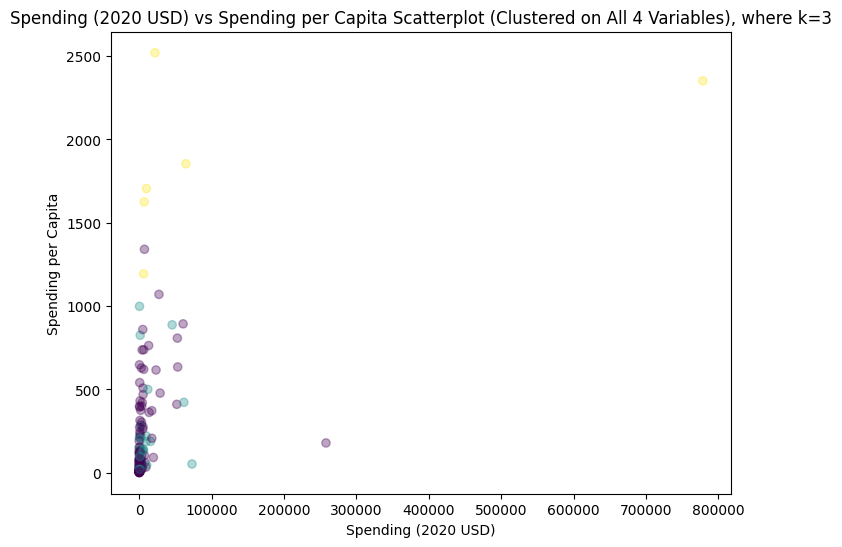

In [406]:
print('The optimal k is k=3, as that is where the elbow bend is located.')

optimal_k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
df_2020['cluster'] = kmeans.fit_predict(df_2020_scaled)

fig, axes = plt.subplots(figsize=(8, 6))
axes.scatter(df_2020['Spending (2020 USD)'], df_2020['Spending per Capita'], alpha=0.35, c=df_2020['cluster'])
axes.set_title('Spending (2020 USD) vs Spending per Capita Scatterplot (Clustered on All 4 Variables), where k=3')
axes.set_xlabel('Spending (2020 USD)')
axes.set_ylabel('Spending per Capita')

In [407]:
print(df_2020.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']].describe())
print()
print(df_2020[['Country', 'cluster']].sort_values('cluster'))
print('k=3 is still the optimal k value according to the scree plot and elbow bend.')

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                           

In [408]:
print('---------------Question 2.5---------------')
print('Yes, the k-MC algorithm did find useful patterns. Countries that had more economic or military power were clustered together, and Countries that had less were also grouped together.')

---------------Question 2.5---------------
Yes, the k-MC algorithm did find useful patterns. Countries that had more economic or military power were clustered together, and Countries that had less were also grouped together.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]